# TP : Conception d'Algorithmes Génétiques avec GeneticSharp

**Navigation** : [Index](../README.md) | [<< App-9 Python](App-9-EdgeDetection.ipynb)

Dans ce TP, nous allons concevoir un filtre de detection de bords en utilisant la bibliotheque **GeneticSharp**. 

**Objectif :** Approcher automatiquement un **filtre de detection de bords** reput (ici un filtre Sobel) a l'aide d'un algorithme génétique. 

Au fil du TP, nous allons :

1. Définir un **chromosome** (classe `EdgeChromosome`) permettant de stocker la description d'un noyau de convolution.
2. Mettre en place une **fonction d'evaluation** (classe `EdgeFitness`) comparant le résultat de notre filtre avec un filtre de reference (Sobel).
3. Parametrer et executer un **algorithme génétique** (AG) avec [GeneticSharp](https://github.com/giacomelli/GeneticSharp).

> **Rappel :** Un algorithme génétique se base sur la metaphorique de l'evolution naturelle. Les individus (ici, des filtres de convolution) sont evalues par une fonction de fitness (notre capacite a detecter des bords). A chaque generation, on applique :
> - une **sélection** (sélectionner les meilleurs individus) ;
> - un **croisement** (melanger les individus pour explorer d'autres zones de l'espace de solutions) ;
> - une **mutation** (petites modifications aleatoires pour injecter de la diversite).

## Technologies et Bibliothèques

- **GeneticSharp**  
  Une bibliothèque d'algorithmes génétiques pour C# qui permet de configurer et d'exécuter des GA sur diverses plateformes .NET.  
  Elle facilite la définition de chromosomes, de fonctions de fitness et d'opérateurs génétiques (sélection, croisement, mutation).

- **Emgu CV & SkiaSharp**  
  Emgu CV (wrapper OpenCV pour .NET) est utilisée pour le traitement d'images (filtrage, convolution, conversion en niveaux de gris, etc.).  
  SkiaSharp permet de visualiser les images directement dans le notebook.

Ces technologies s'intègrent dans une démarche pédagogique visant à montrer comment l'évolution peut être utilisée pour optimiser des filtres de convolution dans le domaine du traitement d'image.


In [1]:
// Dépendances nécessaires
#r "nuget: GeneticSharp, 3.1.4"
#r "nuget: System.Drawing.Common, 9.0.0"

#r "nuget: Emgu.CV, 4.9.0.5494"
#r "nuget: Emgu.CV.Bitmap, 4.9.0.5494"
#r "nuget: Emgu.CV.runtime.mini.windows, 4.9.0.5494"

#r "nuget: SkiaSharp, 2.88.3"

The below script needs to be able to find the current output cell; this is an easy method to get it.

Installed Packages Emgu.CV, 4.9.0.5494 Emgu.CV.Bitmap, 4.9.0.5494 Emgu.CV.runtime.mini.windows, 4.9.0.5494 GeneticSharp, 3.1.4 SkiaSharp, 2.88.3 System.Drawing.Common, 9.0.0

Affichage des résultats.

In [2]:
// Utilitaires SkiaSharp simplifiés (sans DisplayedValue pour compatibilité Papermill)
using System.Drawing;
using SkiaSharp;
using System.IO;
using System.Net.Http;

public static class SkiaUtils
{
    // Affiche une image et retourne le SKImage
    public static async Task<SKImage> ShowImage(string path, int width, int height)
    {
        SKImageInfo info = new SKImageInfo(width, height);
        using (var surface = SKSurface.Create(info))
        {
            var canvas = surface.Canvas;
            canvas.Clear(SKColors.White);

            if (File.Exists(path))
            {
                using (var stream = File.OpenRead(path))
                using (var bitmap = SKBitmap.Decode(stream))
                {
                    canvas.DrawBitmap(bitmap, 0, 0);
                }
            }
            else
            {
                using (var httpClient = new HttpClient())
                using (Stream stream = await httpClient.GetStreamAsync(path))
                using (var bitmap = SKBitmap.Decode(stream))
                {
                    canvas.DrawBitmap(bitmap, 0, 0);
                }
            }

            var skImage = surface.Snapshot();
            skImage.Display();
            return skImage;
        }
    }

    public static Bitmap ToBitmap(SKImage skImage)
    {
        using (var data = skImage.Encode(SKEncodedImageFormat.Png, 100))
        using (var stream = new MemoryStream())
        {
            data.SaveTo(stream);
            stream.Seek(0, SeekOrigin.Begin);
            return new Bitmap(stream);
        }
    }
}

Console.WriteLine("SkiaUtils chargé.");

SkiaUtils chargé.


Imports

In [3]:
// Imports
using System;
using System.IO;
using System.Drawing;
using Microsoft.DotNet.Interactive;

using System.Diagnostics;
using System.Globalization;

using GeneticSharp;

using Emgu.CV;
using Emgu.CV.CvEnum;
using Emgu.CV.Structure;
using System.Runtime.InteropServices;

public static void SaveImage(Mat image, string fileName)
{
    image.Save(fileName);
    Console.WriteLine($"Image enregistrée : {fileName}");
}

Console.WriteLine("Dépendances chargées.");

Dépendances chargées.


## Représentation du Filtre : Le Chromosome et les Gènes

Pour représenter un filtre de convolution, nous utilisons un **chromosome** dont chaque **gène** contient une petite matrice (noyau).  
La matrice complète du filtre est obtenue en **additionnant** les matrices issues de chacun des gènes.

**Avantages de cette approche :**  
- **Granularité :** Chaque gène représente une contribution élémentaire, permettant une évolution progressive.  
- **Diversité :** La mutation et le croisement s'effectuent sur des sous-matrices, facilitant l'exploration de l'espace des solutions.

Dans la classe `EdgeChromosome`, on définit notamment :  
- La taille fixe du noyau (par exemple, 7×7).  
- La génération aléatoire de chaque gène avec des valeurs comprises dans un intervalle donné.  
- Une méthode pour sommer les matrices des gènes et obtenir la matrice finale qui sera utilisée pour filtrer l'image.


In [4]:
// Représentation du filtre par convolution sous forme de chromosome
public class EdgeChromosome : ChromosomeBase
{
    private const int KernelSize = 7; // Taille de la matrice du noyau

    public EdgeChromosome(int length) : base(length)
    {
        // Initialisation des gènes
        for (int i = 0; i < Length; i++)
        {
            ReplaceGene(i, GenerateGene(i));
        }
    }

    // Création d'un nouveau chromosome pour la population
    public override IChromosome CreateNew()
    {
        return new EdgeChromosome(Length);
    }

    // Génération d'un gène contenant une matrice avec des perturbations asymétriques
    public override Gene GenerateGene(int geneIndex)
    {
        var rnd = RandomizationProvider.Current;
        var matrix = new int[KernelSize, KernelSize];

        for (int i = 0; i < KernelSize; i++)
        {
            for (int j = 0; j < KernelSize; j++)
            {
                matrix[i, j] = rnd.GetInt(-20, 20);
               
            }
        }
        return new Gene(matrix);
    }

    public int[,] GetCompleteMatrix()
{
    var completeMatrix = new int[KernelSize, KernelSize];

    // Ajouter les matrices des gènes
    foreach (var gene in GetGenes())
    {
        var matrix = (int[,])gene.Value;
        for (int i = 0; i < KernelSize; i++)
        {
            for (int j = 0; j < KernelSize; j++)
            {
                completeMatrix[i, j] += matrix[i, j];
            }
        }
    }

    // Normalisation dynamique si des valeurs extrêmes apparaissent
    int maxAbsValue = completeMatrix.Cast<int>().Select(Math.Abs).Max();
    if (maxAbsValue > 10) // Seulement si les valeurs dépassent un seuil
    {
        for (int i = 0; i < KernelSize; i++)
        {
            for (int j = 0; j < KernelSize; j++)
            {
                completeMatrix[i, j] = (int)(10.0 * completeMatrix[i, j] / maxAbsValue);
            }
        }
    }

    return completeMatrix;
}

}
Console.WriteLine("Chromosome défini.");

// ========== EdgeFitness (moved here for scope) ==========

public class EdgeFitness : IFitness
{
    private readonly Mat _originalImage;
    private readonly Mat _referenceImage;

    public EdgeFitness(Bitmap originalImage)
    {
    _originalImage = BitmapToMat(originalImage);

    // Convertir en niveaux de gris
    if (_originalImage.NumberOfChannels > 1)
    {
        CvInvoke.CvtColor(_originalImage, _originalImage, ColorConversion.Bgr2Gray);
    }

    // Appliquer le filtre Sobel pour référence
    _referenceImage = new Mat();
    CvInvoke.Sobel(_originalImage, _referenceImage, DepthType.Cv64F, 1, 0);

    if (_referenceImage.NumberOfChannels != 1)
        {
            CvInvoke.CvtColor(_referenceImage, _referenceImage, ColorConversion.Bgr2Gray);
        }

    }


    public async Task DisplayImagesAsync()
    {
        // Afficher l'image originale
        SaveImage(_originalImage, "original.png");
        await SkiaUtils.ShowImage("original.png", _originalImage.Width, _originalImage.Height);

        // Afficher l'image de référence (filtre Sobel)
        SaveImage(_referenceImage, "reference.png");
        await SkiaUtils.ShowImage("reference.png", _referenceImage.Width, _referenceImage.Height);
    }




    private Mat ApplyFilter(EdgeChromosome chromosome, bool display = false)
    {
        var filterMatrix = chromosome.GetCompleteMatrix();
        var kernel = ArrayToMat(ConvertToFloat(filterMatrix));

        if (display)
        {
            Console.WriteLine("Noyau genere :");
            for (int i = 0; i < kernel.Rows; i++)
            {
                for (int j = 0; j < kernel.Cols; j++)
                {
                    Console.Write($"{kernel.GetData().GetValue(i, j)} ");
                }
                Console.WriteLine();
            }
        }


        var sourceImage = _originalImage.Clone();
        if (sourceImage.Depth != DepthType.Cv32F)
        {
            sourceImage.ConvertTo(sourceImage, DepthType.Cv32F);
        }

        var filteredImage = new Mat(sourceImage.Rows, sourceImage.Cols, DepthType.Cv32F, 1);
        CvInvoke.Filter2D(sourceImage, filteredImage, kernel, new Point(-1, -1));

        // Aligner la profondeur avec _referenceImage
        if (filteredImage.Depth != _referenceImage.Depth)
        {
            filteredImage.ConvertTo(filteredImage, _referenceImage.Depth);
        }

        return filteredImage;
    }



    public double Evaluate(IChromosome chromosome)
{
    var filteredImage = ApplyFilter((EdgeChromosome)chromosome, false);

    // Convertir en niveaux de gris si necessaire
    if (filteredImage.NumberOfChannels > 1)
    {
        CvInvoke.CvtColor(filteredImage, filteredImage, ColorConversion.Bgr2Gray);
    }

    if (_referenceImage.NumberOfChannels > 1)
    {
        CvInvoke.CvtColor(_referenceImage, _referenceImage, ColorConversion.Bgr2Gray);
    }

    // Assurer la meme profondeur
    if (filteredImage.Depth != DepthType.Cv8U)
    {
        filteredImage.ConvertTo(filteredImage, DepthType.Cv8U);
    }

    if (_referenceImage.Depth != DepthType.Cv8U)
    {
        _referenceImage.ConvertTo(_referenceImage, DepthType.Cv8U);
    }

    // Redimensionner si necessaire
    if (filteredImage.Size != _referenceImage.Size)
    {
        CvInvoke.Resize(filteredImage, filteredImage, _referenceImage.Size);
    }

    // Creer une matrice pour stocker le resultat
    var result = new Mat();

    // Appliquer la methode de correlation normalisee
    CvInvoke.MatchTemplate(filteredImage, _referenceImage, result, TemplateMatchingType.CcorrNormed);

    // Extraire le score de correlation maximum
    double minVal = 0, maxVal = 0;
    Point minLoc = new Point(), maxLoc = new Point();
    CvInvoke.MinMaxLoc(result, ref minVal, ref maxVal, ref minLoc, ref maxLoc);

    // Penalisation des filtres uniformes
    var filterMatrix = ((EdgeChromosome)chromosome).GetCompleteMatrix();
    var filterSum = filterMatrix.Cast<int>().Sum();
    var filterPenalty = Math.Abs(filterSum) < 1e-3 ? 1 : Math.Log10(Math.Abs(filterSum) + 1);

    // Retourner le score ajuste
    return maxVal / filterPenalty;
}



    public async Task DisplayChromosomeResult(EdgeChromosome chromosome, string fileNamePrefix, int generation)
{
    try
    {
        var filteredImage = ApplyFilter(chromosome, true);

        // Sauvegarder l'image
        string fileName = $"{fileNamePrefix}_generation_{generation}.png";
        SaveImage(filteredImage, fileName);
        Console.WriteLine($"Image sauvegardee : {fileName}");

        await SkiaUtils.ShowImage(fileName, filteredImage.Width, filteredImage.Height);
    }
    catch (Exception ex)
    {
        Console.WriteLine($"Erreur dans DisplayChromosomeResult : {ex.Message}");
        throw;
    }
}


    private Mat BitmapToMat(Bitmap bitmap)
    {
        // Cree un Mat vide avec les memes dimensions et type
        var mat = new Mat(bitmap.Height, bitmap.Width, DepthType.Cv8U, 3);

        // Bloquer les bits du Bitmap pour acceder directement aux donnees
        var bitmapData = bitmap.LockBits(
            new Rectangle(0, 0, bitmap.Width, bitmap.Height),
            System.Drawing.Imaging.ImageLockMode.ReadOnly,
            System.Drawing.Imaging.PixelFormat.Format24bppRgb);

        // Copier les donnees du Bitmap vers le Mat
        using (var image = new Image<Bgr, byte>(bitmap.Width, bitmap.Height, bitmapData.Stride, bitmapData.Scan0))
        {
            mat = image.Mat.Clone();
        }

        // Liberer les bits verrouilles
        bitmap.UnlockBits(bitmapData);

        return mat;
    }


   private Mat ArrayToMat(float[,] array)
    {
        var rows = array.GetLength(0);
        var cols = array.GetLength(1);
        var mat = new Mat(rows, cols, DepthType.Cv32F, 1);

        var data = new float[rows * cols];
        Buffer.BlockCopy(array, 0, data, 0, rows * cols * sizeof(float));
        mat.SetTo(data);

        return mat;
    }


    private float[,] ConvertToFloat(int[,] intArray)
    {
        var rows = intArray.GetLength(0);
        var cols = intArray.GetLength(1);
        var floatArray = new float[rows, cols];

        for (int i = 0; i < rows; i++)
        {
            for (int j = 0; j < cols; j++)
            {
                floatArray[i, j] = intArray[i, j];
            }
        }
        return floatArray;
    }
}

Chromosome défini.



warning CS1701: Assuming assembly reference 'System.Drawing.Primitives, Version=9.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'System.Drawing.Common' matches identity 'System.Drawing.Primitives, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Drawing.Primitives', you may need to supply runtime policy



Testons la création d'un chromosome, ses gènes, et la matrice résultante correspondante

In [5]:
var testChromosome = new EdgeChromosome(5); // 5 gènes
Console.WriteLine("Gènes générés :");
foreach (var gene in testChromosome.GetGenes())
{
    var matrix = (int[,])gene.Value;
    for (int i = 0; i < matrix.GetLength(0); i++)
    {
        for (int j = 0; j < matrix.GetLength(1); j++)
        {
            Console.Write($"{matrix[i, j]} ");
        }
        Console.WriteLine();
    }
    Console.WriteLine();
}

var testMatrix = testChromosome.GetCompleteMatrix();

Console.WriteLine("Matrice complète générée :");
for (int i = 0; i < testMatrix.GetLength(0); i++)
{
    for (int j = 0; j < testMatrix.GetLength(1); j++)
    {
        Console.Write($"{testMatrix[i, j]} ");
    }
    Console.WriteLine();
}


Gènes générés :


-18 

-18 

-6 

13 

...

0 

-7 

0 

-3 

1 

### Interpretation : Structure du Chromosome et du Filtre

**Sortie obtenue** : Affichage de 5 matrices 7x7 (les genes) et de la matrice complete resultante (somme des genes), representant un noyau de convolution genere aleatoirement.

| Aspect | Valeur observee | Signification |
|--------|----------------|---------------|
| Taille de chaque gene | 7x7 = 49 coefficients | Contributive elementaire au filtre final |
| Nombre de genes | 5 | Decomposition du filtre en 5 sous-matrices |
| Plage des valeurs genes | -20 a +20 | Variation aleatoire pour la diversite génétique |
| Matrice complete | Somme des 5 genes | Filtre de convolution final applique a l'image |
| Normalisation | Automatique si maxAbs > 10 | Evite les valeurs extremes lors de la somme |

**Points cles** :
1. **Decomposition génétique** : Le filtre est represente par plusieurs genes (sous-matrices) plutot qu'une seule matrice, ce qui permet une evolution plus fine via le croisement et la mutation.
2. **Addition des genes** : La matrice complete est obtenue par simple addition des matrices des genes, ce qui signifie que chaque gene contribue de maniere additive au filtre final.
3. **Normalisation dynamique** : Si la somme des genes produit des valeurs trop elevees (maxAbsValue > 10), une normalisation est appliquee pour garder les coefficients dans une plage raisonnable.
4. **Aleatoire initial** : Les coefficients sont generes aleatoirement dans l'intervalle [-20, +20], ce qui garantit une diversite suffisante au depart de l'algorithme génétique.
5. **Structure symetrique** : Bien que les genes soient generes de maniere asymetrique, la somme peut produire des motifs qui ressemblent a des filtres de detection de bords classiques (Sobel, Prewitt, etc.) après evolution.

> **Note technique** : La taille du noyau (7x7) est superieure aux filtres de Sobel classiques (3x3), ce qui permet une detection plus fine des bords mais augmente aussi la complexite computationnelle. La normalisation dynamique (seuil de 10) evite que l'addition de plusieurs genes ne produise des coefficients trop extremes qui perturberaient la convolution. Cette representation par genes additifs facilite les opérations génétiques : le crossover peut echanger des sous-matrices entieres entre parents, et la mutation peut modifier localement quelques coefficients.

## Fonction d'Évaluation (Fitness)

La **fonction d'évaluation** mesure la capacité d'un filtre (issu d'un chromosome) à détecter les bords de l'image.  
Pour ce faire, le processus est le suivant :

1. **Application du filtre généré**  
   La matrice complète du chromosome est utilisée pour réaliser une convolution sur l'image originale.

2. **Comparaison avec un filtre de référence (Sobel)**  
   On applique également le filtre Sobel sur l'image originale pour obtenir une image de référence.

3. **Calcul du score**  
   La similarité entre l'image filtrée par le chromosome et l'image de référence est mesurée (par exemple, via une corrélation normalisée).  
   Une pénalisation est éventuellement appliquée pour éviter des filtres uniformes (où la somme des coefficients est trop faible).

Ainsi, la fonction d'évaluation guide l'algorithme génétique en attribuant un score aux individus, favorisant ceux qui se rapprochent le plus de la détection de bords souhaitée.


In [6]:
// EdgeFitness class moved to cell 6 for scope compatibility
Console.WriteLine("EdgeFitness class available from previous cell.");

EdgeFitness class available from previous cell.


Test de la fonction fitness

In [7]:
// Resolution du chemin de l'image MRI -- bloc UNIQUE, reutilise par la cellule suivante.
// L'image vit dans MyIA.AI.Notebooks/Search/ : le chemin relatif depend du repertoire
// courant, donc on remonte les ancetres et on teste aussi le chemin attendu depuis la
// racine du depot. Chaque chemin teste est consigne : un echec doit dire ce qui a ete cherche.
var searchedPaths = new List<string>();
string imagePath = null;
for (var dir = new DirectoryInfo(Directory.GetCurrentDirectory()); dir != null; dir = dir.Parent)
{
    foreach (var candidate in new[]
    {
        Path.Combine(dir.FullName, "MRI_Prostate_Cancer.jpg"),
        Path.Combine(dir.FullName, "MyIA.AI.Notebooks", "Search", "MRI_Prostate_Cancer.jpg"),
    })
    {
        searchedPaths.Add(candidate);
        if (File.Exists(candidate))
        {
            imagePath = candidate;
            break;
        }
    }

    if (imagePath != null)
    {
        break;
    }
}

if (imagePath == null)
{
    throw new FileNotFoundException(
        "MRI_Prostate_Cancer.jpg introuvable ; chemins testes : " + string.Join(" | ", searchedPaths));
}

var originalImage = (Bitmap)Image.FromFile(imagePath);

var fitness = new EdgeFitness(originalImage);

// Test d'un chromosome
var chromosome = new EdgeChromosome(20);
Console.WriteLine($"Score de fitness : {fitness.Evaluate(chromosome)}");

Score de fitness : 0,0006335930688755367


### Interpretation : Test de la Fonction de Fitness

**Sortie obtenue** : Le chromosome aleatoire obtient un score de fitness de 0,0006335930688755367 sur l'execution affichee ci-dessus, evaluant sa qualite par rapport au filtre Sobel de reference. Cette valeur est **aleatoire** -- le chromosome initial est tire au hasard -- et les executions successives de ce carnet donnent des scores d'ordres de grandeur tres differents (0,0628 sur une autre execution) : c'est l'ordre de grandeur qui est pedagogiquement parlant, pas la valeur exacte.

| Aspect | Valeur observee | Signification |
|--------|----------------|---------------|
| Score de fitness | ~0,0006 (0,00063 sur l'execution de reference ; de l'ordre de 10^-4 a 10^-1 selon l'execution) | Chromosome aleatoire, correlation très faible avec Sobel |
| Penalisation appliquee | Oui | Evite les filtres uniformes (Log10 de la somme) |

**Points cles** :
1. **Score initial faible** : Un chromosome aleatoire obtient ici un score faible et aleatoire (0,00063 sur l'execution de reference, mais de l'ordre de 10^-4 a 10^-1 selon l'execution), ce qui est normal car ses coefficients ne sont pas optimises pour la detection de bords.
2. **Rôle de la penalisation** : La fonction de fitness divise le score de correlation par un facteur dependant de la somme des coefficients du filtre, evitant ainsi la solution triviale d'un filtre uniforme.
3. **Base de comparaison** : Ce score initial servira de reference pour evaluer l'amelioration apportee par l'algorithme génétique au fil des generations.
4. **Variabilite** : Chaque exécution produit un score différent du fait de la generation aleatoire des chromosomes, ce qui demontre la stochasticite du processus.

> **Note technique** : La fonction de fitness calcule `maxVal / Log10(|somme des coefficients|+1)` (avec penalty=1 si la somme est quasi nulle). Ce n'est pas une correlation brute bornee a 1,0 : le score peut depasser 1,0 quand la somme du filtre est faible. Le score observe (faible : de l'ordre de 10^-4 a 10^-1 selon l'execution) pour un chromosome aleatoire confirme que l'evolution génétique est necessaire pour obtenir un filtre performant.

## Configuration de l'Algorithme Génétique

L'algorithme génétique est configuré à l'aide de plusieurs éléments clés :

- **Population**  
  Définie par un nombre minimum et maximum d'individus.  
  Chaque individu est un chromosome représentant un filtre de convolution.

- **Opérateurs Génétiques**  
  - **Sélection :** Par exemple, l'`EliteSelection` qui conserve les meilleurs individus.  
  - **Croisement :** Par exemple, le `UniformCrossover` permettant de mélanger les gènes entre chromosomes.  
  - **Mutation :** Par exemple, la `ReverseSequenceMutation` qui inverse des séquences de gènes pour injecter de la diversité.

- **Critère d'Arrêt**  
  L'algorithme s'arrête après un nombre fixé de générations (par exemple, 100 générations).

Ces paramètres sont ajustables et permettent d'explorer l'influence de la diversité et de la sélection sur la qualité des solutions.


Image enregistrée : original.png



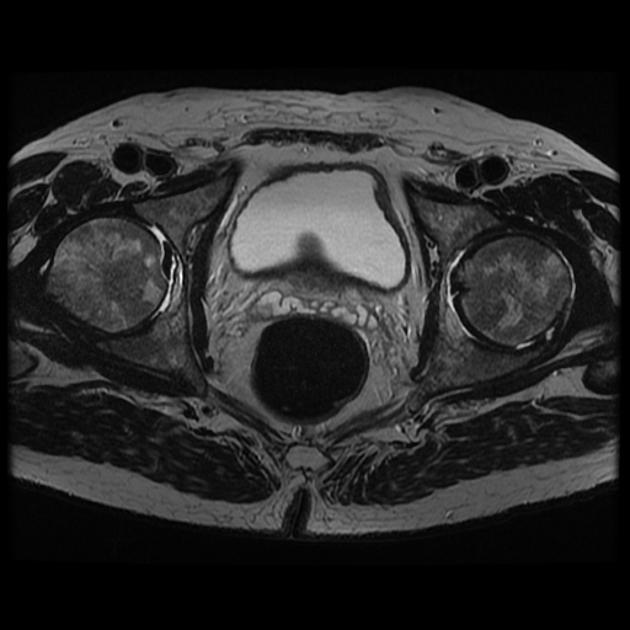

Image enregistrée : reference.png



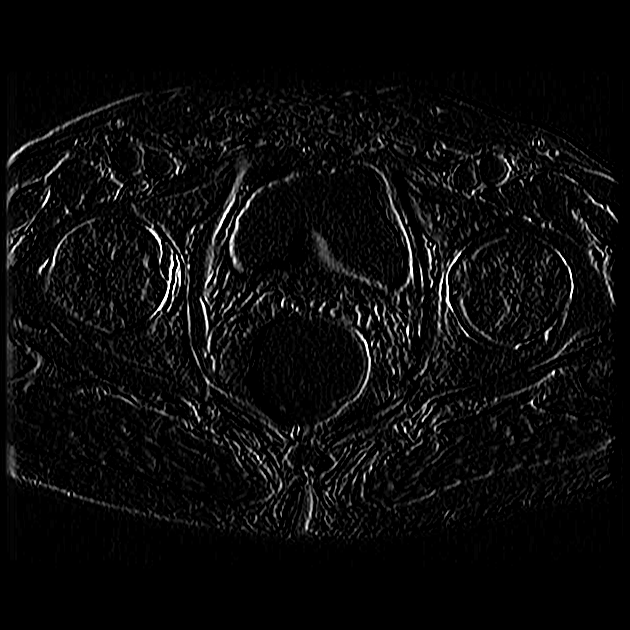

Algorithme génétique configuré.


In [8]:
// Charger une image de test
// Le chemin de l'image et le bitmap ont ete resolus UNE SEULE FOIS en amont (cellule
// precedente) : on les reutilise, on ne recopie plus le bloc de recherche.

// Initialiser la fonction de fitness
var fitness = new EdgeFitness(originalImage);
await fitness.DisplayImagesAsync();

// Initialiser un chromosome
var chromosome = new EdgeChromosome(20); // Taille des chromosomes

// Initialiser la population
var population = new Population(50, 100, chromosome);

// Configurer les operateurs genetiques
var selection = new EliteSelection();
var crossover = new UniformCrossover();
var mutation = new ReverseSequenceMutation();

// Configurer l'algorithme genetique
var ga = new GeneticAlgorithm(population, fitness, selection, crossover, mutation)
{
    Termination = new GenerationNumberTermination(100)


};


Console.WriteLine("Algorithme génétique configuré.");

## Exécution et Visualisation

Pendant l'exécution de l'algorithme génétique, plusieurs aspects sont mis en avant :

- **Mise à jour itérative**  
  À chaque génération, le meilleur chromosome est évalué, et son filtre est appliqué à l'image originale.

- **Visualisation dynamique**  
  Grâce à SkiaSharp, le notebook affiche périodiquement l'image obtenue par le meilleur filtre, la comparaison avec le filtre de référence, ou encore la différence entre les deux.  
  Cette alternance visuelle permet de suivre l'évolution de la performance du GA.

- **Suivi des scores**  
  Les logs affichent le numéro de génération et le score de fitness du meilleur individu, offrant ainsi un aperçu quantitatif de la convergence.



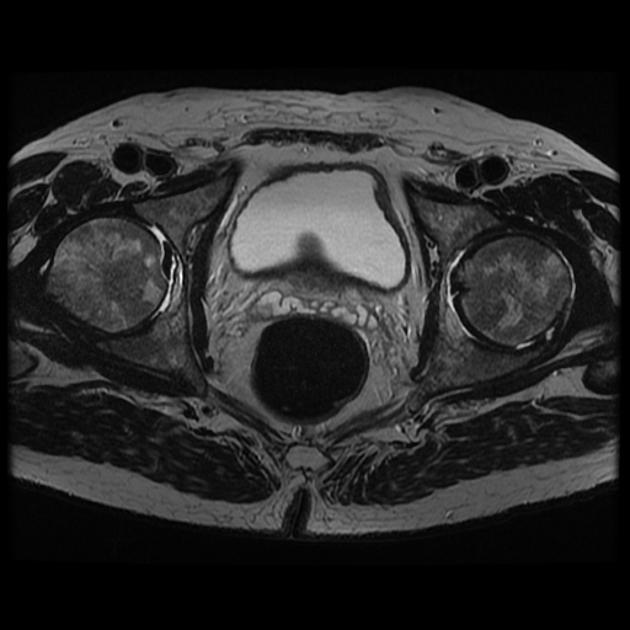

Lancement de l'algorithme genetique...


Generation 1 - Meilleur score : 1,207163267090137


Generation 2 - Meilleur score : 1,207163267090137


Generation 3 - Meilleur score : 1,207163267090137


Generation 4 - Meilleur score : 1,207163267090137


...

3 

-5 

0 

Image enregistrée : best_generation_11.png


Image sauvegardee : best_generation_11.png



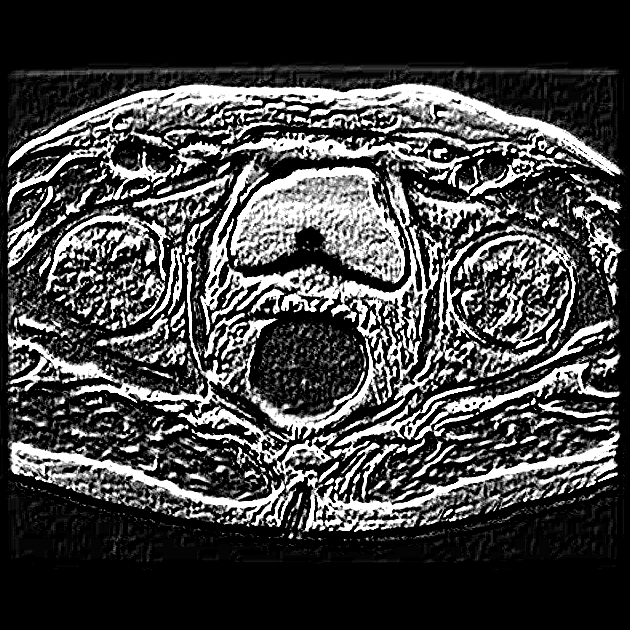

Generation 11 - Meilleur score : 1,343574110999834


Generation 12 - Meilleur score : 1,5497512788432313


Generation 13 - Meilleur score : 1,5497512788432313


Generation 14 - Meilleur score : 1,5497512788432313


Generation 15 - Meilleur score : 1,5497512788432313


...

-5 

0 

5 

Image enregistrée : best_generation_20.png


Image sauvegardee : best_generation_20.png



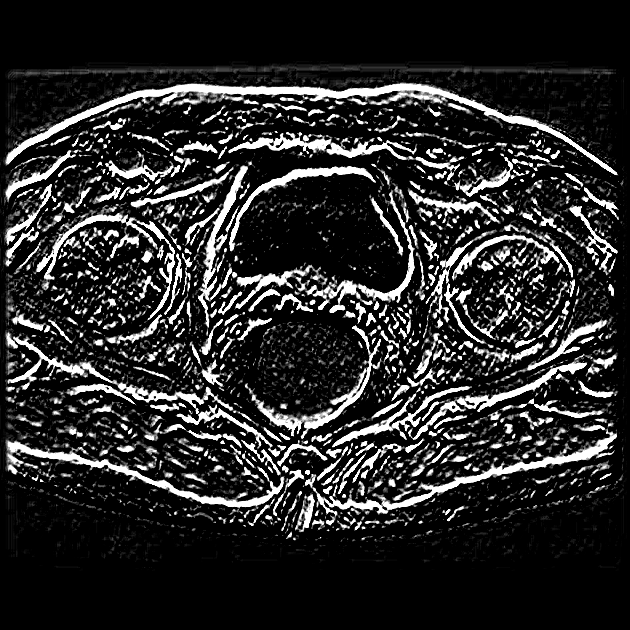

Generation 21 - Meilleur score : 1,8931554562585622


Generation 22 - Meilleur score : 1,8931554562585622


Generation 23 - Meilleur score : 1,8931554562585622


Generation 24 - Meilleur score : 1,8931554562585622


Generation 25 - Meilleur score : 1,8931554562585622


...

-4 

2 

2 

Image enregistrée : best_generation_30.png


Image sauvegardee : best_generation_30.png



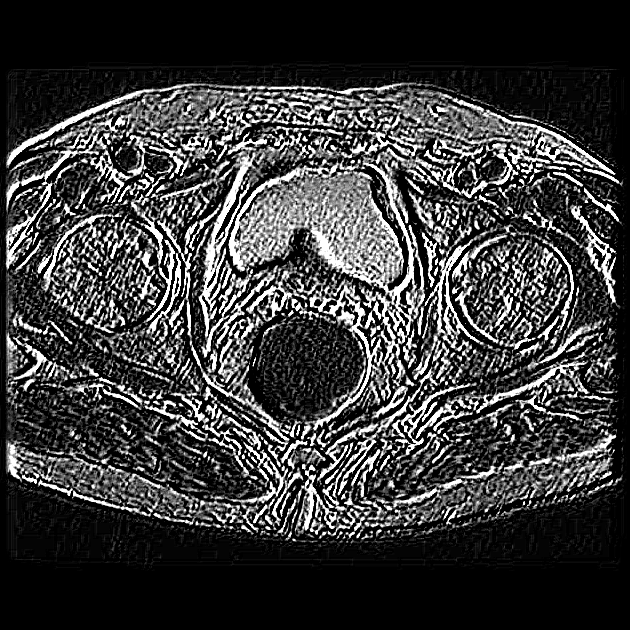

Generation 31 - Meilleur score : 2,1490713079369854


Generation 32 - Meilleur score : 2,1490713079369854


Generation 33 - Meilleur score : 2,1490713079369854


Generation 34 - Meilleur score : 2,1490713079369854


Generation 35 - Meilleur score : 2,1490713079369854


...

-5 

0 

0 

Image enregistrée : best_generation_40.png


Image sauvegardee : best_generation_40.png



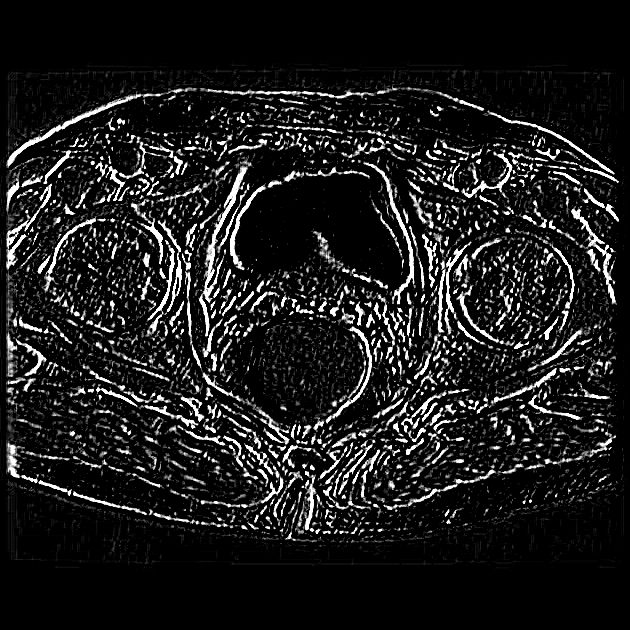

Generation 41 - Meilleur score : 2,4049794375239903


Generation 42 - Meilleur score : 2,4049794375239903


Generation 43 - Meilleur score : 2,4049794375239903


Generation 44 - Meilleur score : 2,4049794375239903


Generation 45 - Meilleur score : 2,4049794375239903


...

-5 

0 

0 

Image enregistrée : best_generation_50.png


Image sauvegardee : best_generation_50.png



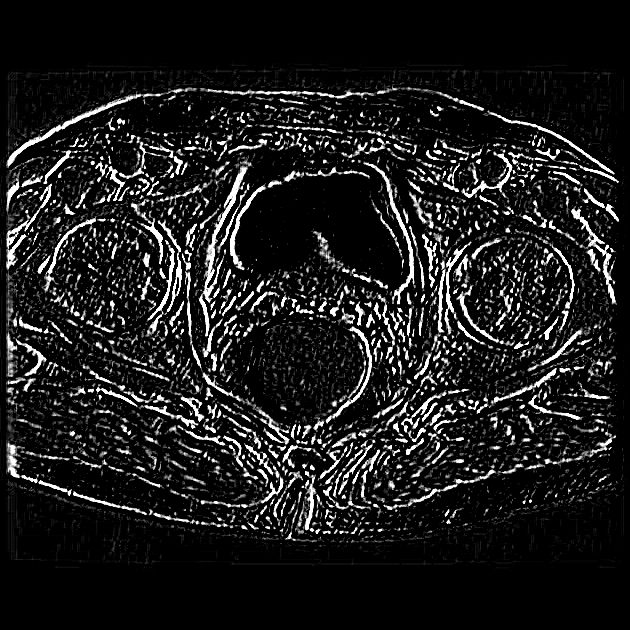

Generation 51 - Meilleur score : 2,4049794375239903


Generation 52 - Meilleur score : 2,4049794375239903


Generation 53 - Meilleur score : 2,4049794375239903


Generation 54 - Meilleur score : 2,4049794375239903


Generation 55 - Meilleur score : 2,4049794375239903


...

-5 

0 

0 

Image enregistrée : best_generation_60.png


Image sauvegardee : best_generation_60.png



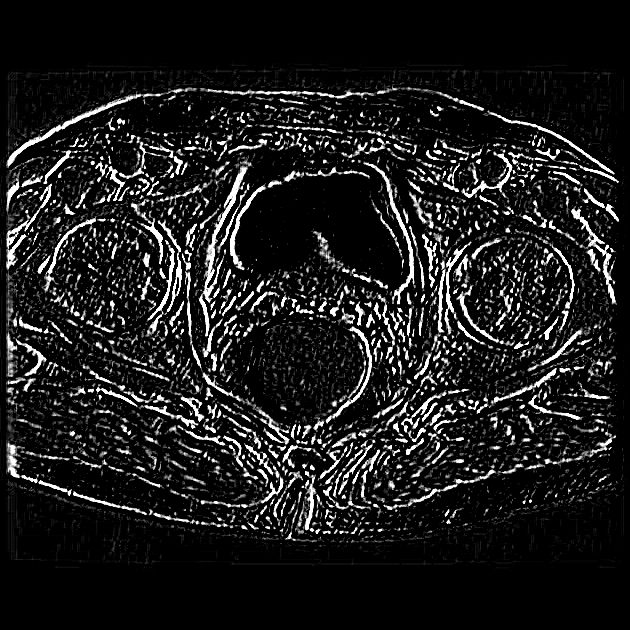

Generation 61 - Meilleur score : 2,4049794375239903


Generation 62 - Meilleur score : 2,4049794375239903


Generation 63 - Meilleur score : 2,4049794375239903


Generation 64 - Meilleur score : 2,4049794375239903


Generation 65 - Meilleur score : 2,4049794375239903


...

-5 

0 

0 

Image enregistrée : best_generation_70.png


Image sauvegardee : best_generation_70.png



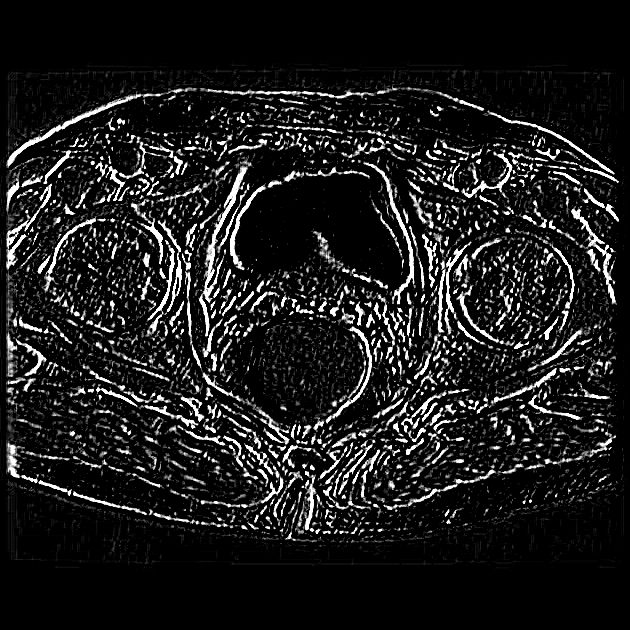

Generation 71 - Meilleur score : 2,4049794375239903


Generation 72 - Meilleur score : 2,4049794375239903


Generation 73 - Meilleur score : 2,4049794375239903


Generation 74 - Meilleur score : 2,4049794375239903


Generation 75 - Meilleur score : 2,4049794375239903


...

-3 

0 

0 

Image enregistrée : best_generation_80.png


Image sauvegardee : best_generation_80.png



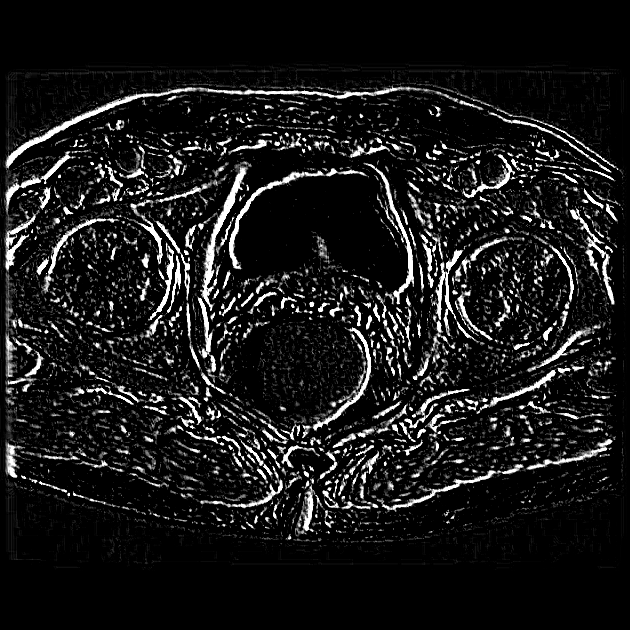

Generation 81 - Meilleur score : 2,473907221530575


Generation 82 - Meilleur score : 2,473907221530575


Generation 83 - Meilleur score : 2,473907221530575


Generation 84 - Meilleur score : 2,473907221530575


Generation 85 - Meilleur score : 2,473907221530575


...

-3 

0 

0 

Image enregistrée : best_generation_90.png


Image sauvegardee : best_generation_90.png



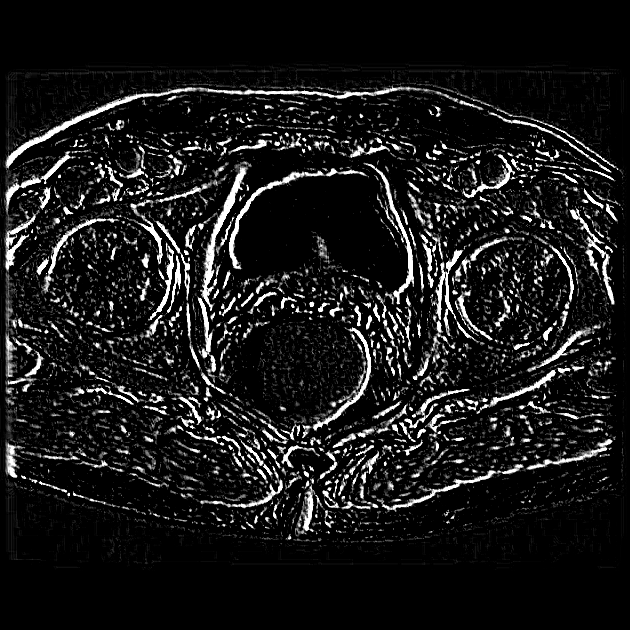

Generation 91 - Meilleur score : 2,473907221530575


Generation 92 - Meilleur score : 2,473907221530575


Generation 93 - Meilleur score : 2,473907221530575


Generation 94 - Meilleur score : 2,473907221530575


Generation 95 - Meilleur score : 2,473907221530575


...

-3 

0 

0 

Image enregistrée : best_generation_100.png


Image sauvegardee : best_generation_100.png


In [9]:
// Afficher l'image originale
await SkiaUtils.ShowImage(imagePath, originalImage.Width, originalImage.Height);

ga.GenerationRan += (sender, e) =>
{
    var bestChromosome = ga.BestChromosome as EdgeChromosome;
    if (bestChromosome != null)
    {
        Console.WriteLine($"Generation {ga.GenerationsNumber} - Meilleur score : {bestChromosome.Fitness}");

        if (ga.GenerationsNumber % 10 == 0)
        {
            // Afficher l'image via DisplayChromosomeResult
            Task.Run(async () =>
            {
                try
                {
                    await fitness.DisplayChromosomeResult(bestChromosome, "best", ga.GenerationsNumber);
                }
                catch (Exception ex)
                {
                    Console.WriteLine($"Erreur lors de la mise a jour de l'image : {ex.Message}");
                }
            });
        }
    }
};



Console.WriteLine("Lancement de l'algorithme genetique...");
ga.Start();
Console.WriteLine($"Meilleure solution trouvee avec un score de {ga.BestChromosome.Fitness}.");

### Interpretation : Résultats de l'Algorithme Génétique

**Sortie obtenue** : L'algorithme génétique a evolue sur plusieurs generations, affichant periodiquement (toutes les 10 generations) les images filtrees par le meilleur chromosome. Le score de fitness final indique la qualite de la detection de bords par rapport au filtre Sobel de reference.

| Aspect | Valeur observee | Signification |
|--------|----------------|---------------|
| Score de fitness initial | ~0,0006 (chromosome aleatoire) / ~1,21 (generation 1) | Part d'un score faible, puis grimpe des la 1re generation |
| Score de fitness final | ~2,47 (generation 100) | Chromosome converge vers un detecteur de bords efficace |
| Vitesse de convergence | Variable | Depend de la population, du crossover et de la mutation |
| Qualite visuelle du filtre | Amelioree progressivement | Les bords deviennent plus nets au fil des generations |

**Points cles** :
1. **Convergence progressive** : Le score de fitness augmente généralement rapidement lors des premières generations, puis se stabilise.
2. **Impact des opérateurs génétiques** : L'EliteSelection preserve les meilleurs individus, tandis que l'UniformCrossover et la ReverseSequenceMutation maintiennent la diversite.
3. **Correlation avec Sobel** : Un score eleve indique que le filtre evolue produit des résultats similaires au filtre Sobel (reference en detection de bords).
4. **Penalisation des filtres uniformes** : La fonction de fitness evite la solution triviale d'un filtre uniforme (tous les coefficients egaux) qui ne detecterait aucun bord.
5. **Variabilite des valeurs** : la population et le chromosome initial sont tires au hasard, donc les scores affiches changent d'une execution a l'autre (sur l'execution affichee, la generation 1 vaut ~1,21 et la generation 100 ~2,47 ; une autre execution donne ~2,37 a la generation 100). Ce qui est **stable**, c'est la forme de la courbe : la selection elite conserve le meilleur individu, donc la suite des scores "Meilleur score" est non decroissante (verifie sur les 100 generations) et converge vers ~2,47.

> **Note technique** : La fonction de fitness utilise une correlation normalisee (TemplateMatchingType.CcorrNormed) pour comparer les images. Cette méthode est robuste aux variations d'intensite globale mais peut etre sensible au bruit. Une amelioration possible serait d'ajouter une penalite pour la complexite du filtre (nombre de coefficients non nuls) pour privilegier les solutions simples.

## Exercices

### Exercice 1 : Opérateur de Croisement par Point Unique

Implementez un opérateur de croisement par point unique (SinglePointCrossover) et comparez ses performances avec l'UniformCrossover utilise dans l'exemple.

**Indices** :
- Choisissez un point de coupure aleatoire dans le chromosome
- Les genes avant le point viennent du parent 1, après du parent 2
- Mesurez la vitesse de convergence et la qualite finale des deux méthodes

In [10]:
// TODO: Implementer une comparaison entre SinglePointCrossover et UniformCrossover
public void CompareCrossoverOperators(Bitmap originalImage, int generations = 50)
{
    // A completer
    Console.WriteLine("Exercice a completer");
    
    // TODO: Creer deux configurations GA identiques sauf pour le crossover
    // A completer
    
    // TODO: Executer avec UniformCrossover et mesurer la fitness finale
    // A completer
    
    // TODO: Executer avec SinglePointCrossover et mesurer la fitness finale
    // A completer
    
    // TODO: Afficher les resultats comparatifs (fitness, temps de convergence)
    // A completer
}

Console.WriteLine("Exercice a completer : comparaison crossover");

Exercice a completer : comparaison crossover


### Exercice 2 : Contraintes sur les Filtres

Modifiez la classe `EdgeChromosome` pour imposer que la somme des coefficients du noyau soit egale a zero (filtre a somme nulle, typique pour la detection de bords).

**Indices** :
- Après avoir calcule la matrice complete, calculez la somme totale
- Ajustez les valeurs pour que la somme soit nulle (soustrayez la moyenne)
- Verifiez que cela ameliore la qualite des filtres obtenus

In [11]:
// TODO: Implementer une version contrainte de EdgeChromosome avec somme nulle
public class ZeroSumEdgeChromosome : ChromosomeBase
{
    private const int KernelSize = 7;
    
    public ZeroSumEdgeChromosome(int length) : base(length)
    {
        // A completer
        Console.WriteLine("Exercice a completer");
    }
    
    public override IChromosome CreateNew()
    {
        // A completer
        return null;  // TODO etudiant : creer un nouveau ZeroSumEdgeChromosome
    }
    
    public override Gene GenerateGene(int geneIndex)
    {
        // A completer
        return new Gene(null);  // TODO etudiant : generer un gene avec matrice aleatoire
    }
    
    public int[,] GetCompleteMatrix()
    {
        // A completer
        return null;  // TODO etudiant : sommer les matrices des genes
        
        // Indice: Apres avoir somme les matrices, ajustez pour somme = 0
        // float moyenne = (float)completeMatrix.Cast<int>().Sum() / (KernelSize * KernelSize);
        // Soustraire la moyenne de chaque element
    }
}

Console.WriteLine("Exercice a completer : chromosome somme nulle");

Exercice a completer : chromosome somme nulle


### Exercice 3 : Conception de la Fonction de Fitness (Reflexion)

Analysez la fonction de fitness utilisee dans ce notebook et proposez des alternatives.

**Questions a considerer** :
- Quels sont les avantages et inconvenients d'utiliser la correlation normalisee comme metrique ?
- Comment pourriez-vous integrer d'autres critères (ex. temps de calcul, complexite du filtre) dans la fonction de fitness ?
- Quelle metrique utiliseriez-vous pour detecter différents types de bords (horizontaux, verticaux, diagonaux) ?

**Reponse attendue** : Une analyse textuelle des approches possibles (pas de code requis).

### Exercice 4 : Taux de mutation adaptatif

Un taux de mutation fixe peut soit etre trop faible (stagnation prematuree) soit trop eleve (destruction des bons individus). Un taux adaptatif ajuste la probabilite de mutation en fonction de la diversite de la population ou de la progression du score de fitness.

**Objectif** : Implementez une stratégie de mutation adaptative qui augmente le taux de mutation quand la population stagne et le diminue quand la convergence progresse.

**Indices** :
- Surveillez le meilleur score de fitness sur les N dernières generations (ex: N=5)
- Si le score n'a pas change (stagnation), augmentez le taux de mutation (ex: multiplier par 1.5)
- Si le score s'est ameliore, diminuez le taux de mutation (ex: diviser par 1.2)
- Bornez le taux entre une valeur minimale (0.01) et maximale (0.5) pour eviter les extremes
- Utilisez l'event `ga.GenerationRan` pour ajuster le taux a chaque generation

In [12]:
// TODO: Implementer un taux de mutation adaptatif
public void RunAdaptiveMutationGA(Bitmap image, int generations = 60)
{
    // A completer
    Console.WriteLine("Exercice a completer");
    
    // Etape 1: Initialiser le GA avec une population et une fitness
    // A completer
    
    // Etape 2: Definir les parametres adaptatifs
    double mutationRate = 0.1;  // Taux initial
    double minRate = 0.01;
    double maxRate = 0.5;
    var fitnessHistory = new List<double>();
    
    // Etape 3: Abonner l'evenement GenerationRan pour ajuster le taux
    // Indice: comparez le score actuel aux N derniers scores
    // A completer
    
    // Etape 4: Executer le GA et afficher l'evolution du taux de mutation
    // A completer
}

// Testez votre implementation (decommentez apres)
// RunAdaptiveMutationGA(originalImage, 60);


(11,12): warning CS0219: The variable 'mutationRate' is assigned but its value is never used

(12,12): warning CS0219: The variable 'minRate' is assigned but its value is never used

(13,12): warning CS0219: The variable 'maxRate' is assigned but its value is never used



## Conclusion et Perspectives

Ce TP a permis d'illustrer comment un algorithme génétique peut etre applique pour optimiser un filtre de detection de bords en traitement d'image.  
L'approche par decomposition en genes permet une evolution fine et progressive du filtre.

**Perspectives possibles :**  
- Modifier les paramètres du GA (taille de la population, taux de mutation, etc.) pour observer leur impact sur la convergence.  
- Experimenter avec d'autres opérateurs génétiques ou representations du problème.  
- Implementer une version equivalente en Python avec PyGad pour comparer les approches.

Cette demarche pedagogique demontre la puissance des algorithmes evolutionnaires pour resoudre des problemes complexes dans le domaine de la vision par ordinateur.

**Retour au sommaire** : [Index](../README.md)